# Sinergia fraterna: métrica de banda de resonancia basada en la estructura del árbol MDFD
**Detección de Anomalías en Sistemas Críticos, PUCV (Prof. N. Rodríguez)** · Cristóbal Martínez Arochas

Este notebook reproduce el informe `informe_sinergia_fraterna.pdf`:
1. MDFD con la notación del curso y verificación de sus propiedades (reconstrucción y ortogonalidad).
2. **Identidad de herencia de curtosis** $K_p = w_a^2K_a + w_b^2K_b + S_p$, verificada al nivel de precisión de máquina.
3. Sinergograma (métrica ciega $Z$) frente al kurtogram en una simulación con verdad conocida.
4. Espectro de sinergia $s(\alpha)$ (versión cíclica) frente al SES clásico.
5. CWRU: el registro 282 de clases y el registro 105.

Requiere `mdfd_sinergia.py` y `simulador.py` en la misma carpeta (y `figuras.py` para los gráficos).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from mdfd_sinergia import *
from simulador import simulate
import figuras as F          # estilos y funciones de gráficos
FS, L = 12000, 6
%matplotlib inline

## 1. MDFD y la identidad de herencia

In [2]:
rng = np.random.default_rng(1)
x = simulate(fs=FS, fn=3500, snr_db=-12, rng=rng)       # falla de pista externa (fd=107,3 Hz) en resonancia de 3,5 kHz
T = MDFDTree(x, FS, L)

# (a) reconstrucción por nivel y (b) padre = suma de hijos
for l in range(L + 1):
    rec = sum(T.real(l, m) for m in range(2 ** l))
    print(f"nivel {l}: error relativo de reconstrucción = {np.linalg.norm(T.x - rec) / np.linalg.norm(T.x):.1e}")

filas = []
for l in range(L):
    for m in range(2 ** l):
        t = heredity_terms(T.z(l + 1, 2 * m), T.z(l + 1, 2 * m + 1))
        Kp = complex_kurtosis(T.z(l, m))
        filas.append(dict(l=l, m=m, Kp=Kp, heredada=t['inherited'], S=t['S'], S_cov=t['S_cov'],
                          S_fase=t['S_fase'], error_identidad=abs(Kp - t['inherited'] - t['S'])))
df = pd.DataFrame(filas)
print('máximo |K_p - (heredada + S)| =', df.error_identidad.max())
df.sort_values('S', ascending=False).head(8)

nivel 0: error relativo de reconstrucción = 4.8e-16
nivel 1: error relativo de reconstrucción = 4.8e-16
nivel 2: error relativo de reconstrucción = 4.8e-16
nivel 3: error relativo de reconstrucción = 4.9e-16


nivel 4: error relativo de reconstrucción = 4.9e-16


nivel 5: error relativo de reconstrucción = 5.1e-16


nivel 6: error relativo de reconstrucción = 5.4e-16


máximo |K_p - (heredada + S)| = 1.0937431516033769e-15


,l,m,Kp,heredada,S,S_cov,S_fase,error_identidad
11,3,4,0.125631,0.010436,0.115195,0.043587,0.071608,4.163336e-17
5,2,2,0.122734,0.042689,0.080045,0.033484,0.046561,4.024558e-16
42,5,11,0.084894,0.013665,0.071229,0.059724,0.011505,4.440892e-16
24,4,9,0.041046,-0.030088,0.071134,0.010844,0.060290,5.551115e-17
54,5,23,0.056080,-0.010203,0.066283,0.065921,0.000363,6.245005e-16
51,5,20,0.033915,-0.006223,0.040137,0.039635,0.000502,5.759282e-16
17,4,2,0.030197,-0.006673,0.036870,0.038341,-0.001471,3.885781e-16
4,2,1,0.024102,-0.010373,0.034475,0.019187,0.015287,5.342948e-16


## 2. Kurtogram vs. sinergograma (simulación, SNR −15 dB)

{'K': (6, 45), 'Z': (3, 4), 'hbrK': (-inf, False), 'hbrZ': (8.612768341741287, np.True_)}


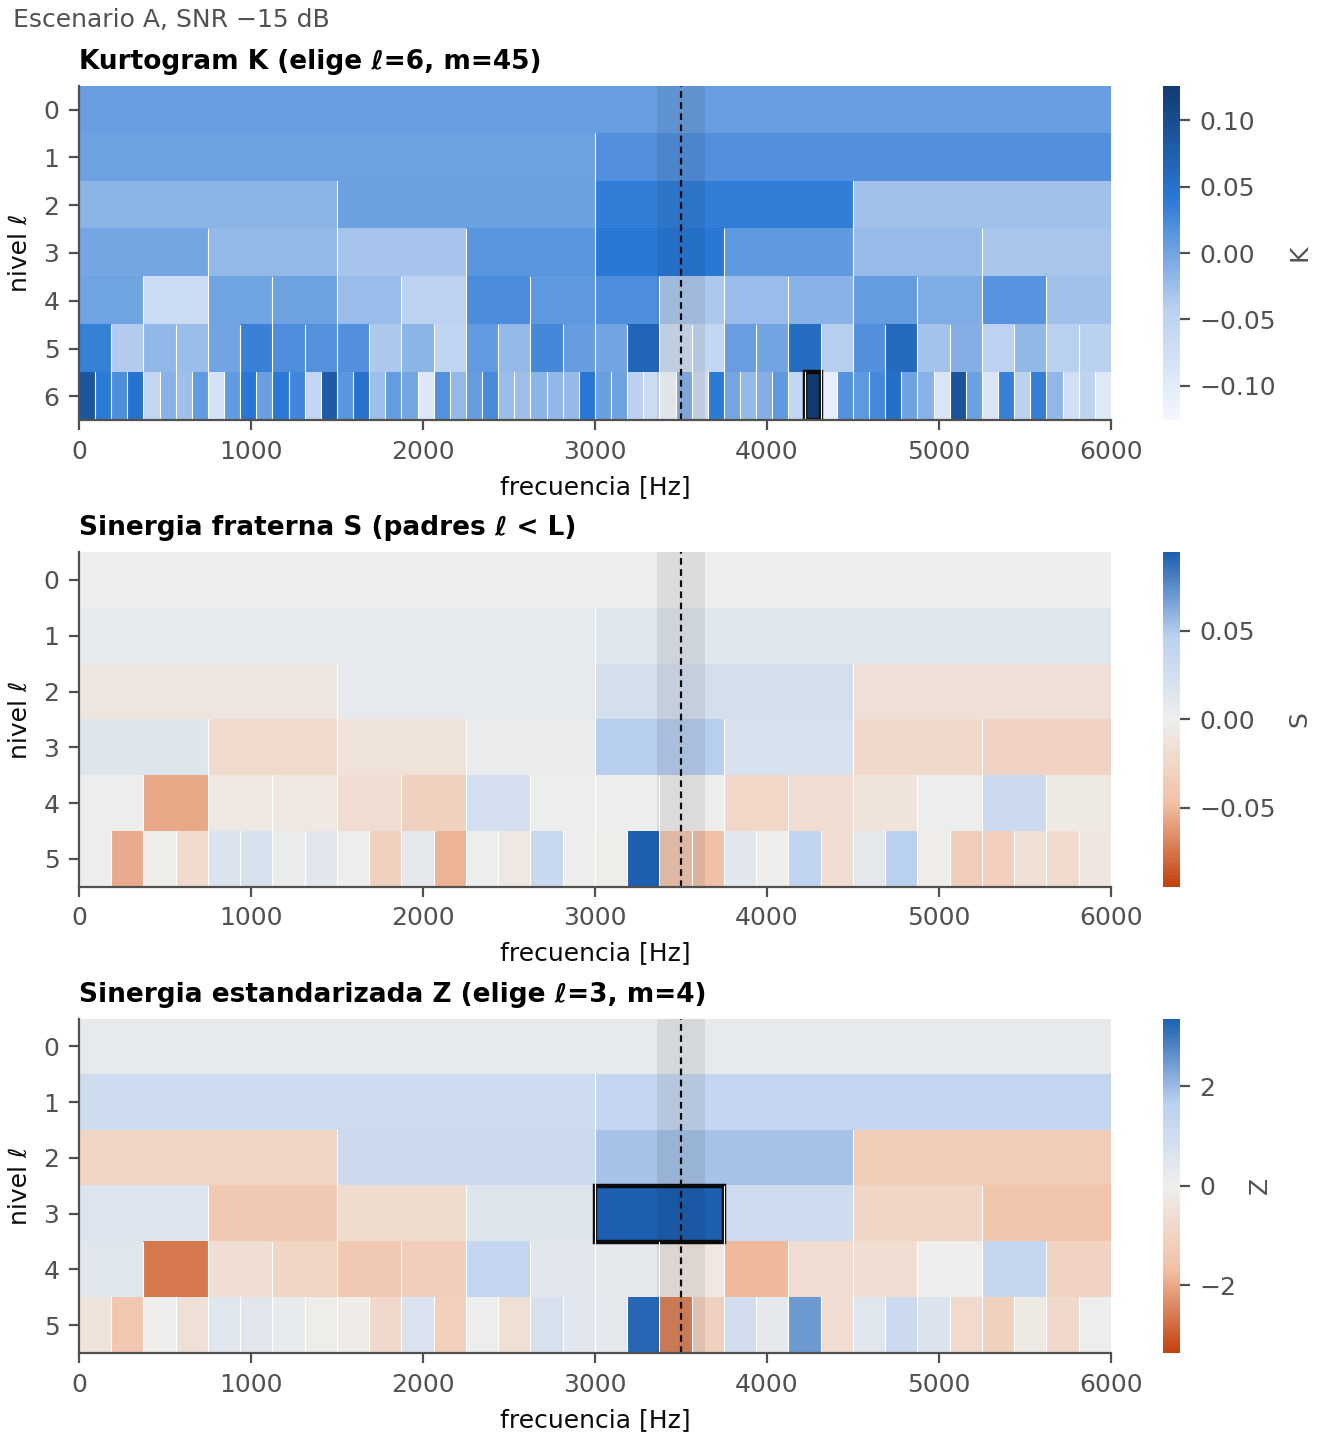

In [3]:
print(F.fig_maps_sim(dict(fn=3500), -15, 3, 'mapas_base.png', 'Escenario A, SNR −15 dB'))
from IPython.display import Image
Image('fig/mapas_base.png')

El kurtogram elige un nodo del nivel 6 con ~94 Hz de ancho, **más angosto que fd**, por la varianza de estimación que crece como $2^{\ell/2}$. El sinergograma elige la banda 3000–3750 Hz, que contiene la resonancia.
Caso de frontera diádica (resonancia exactamente en 3 kHz):

{'K': (6, 6), 'Z': (1, 0), 'hbrK': (-inf, False), 'hbrZ': (4.980234165148368, np.True_)}


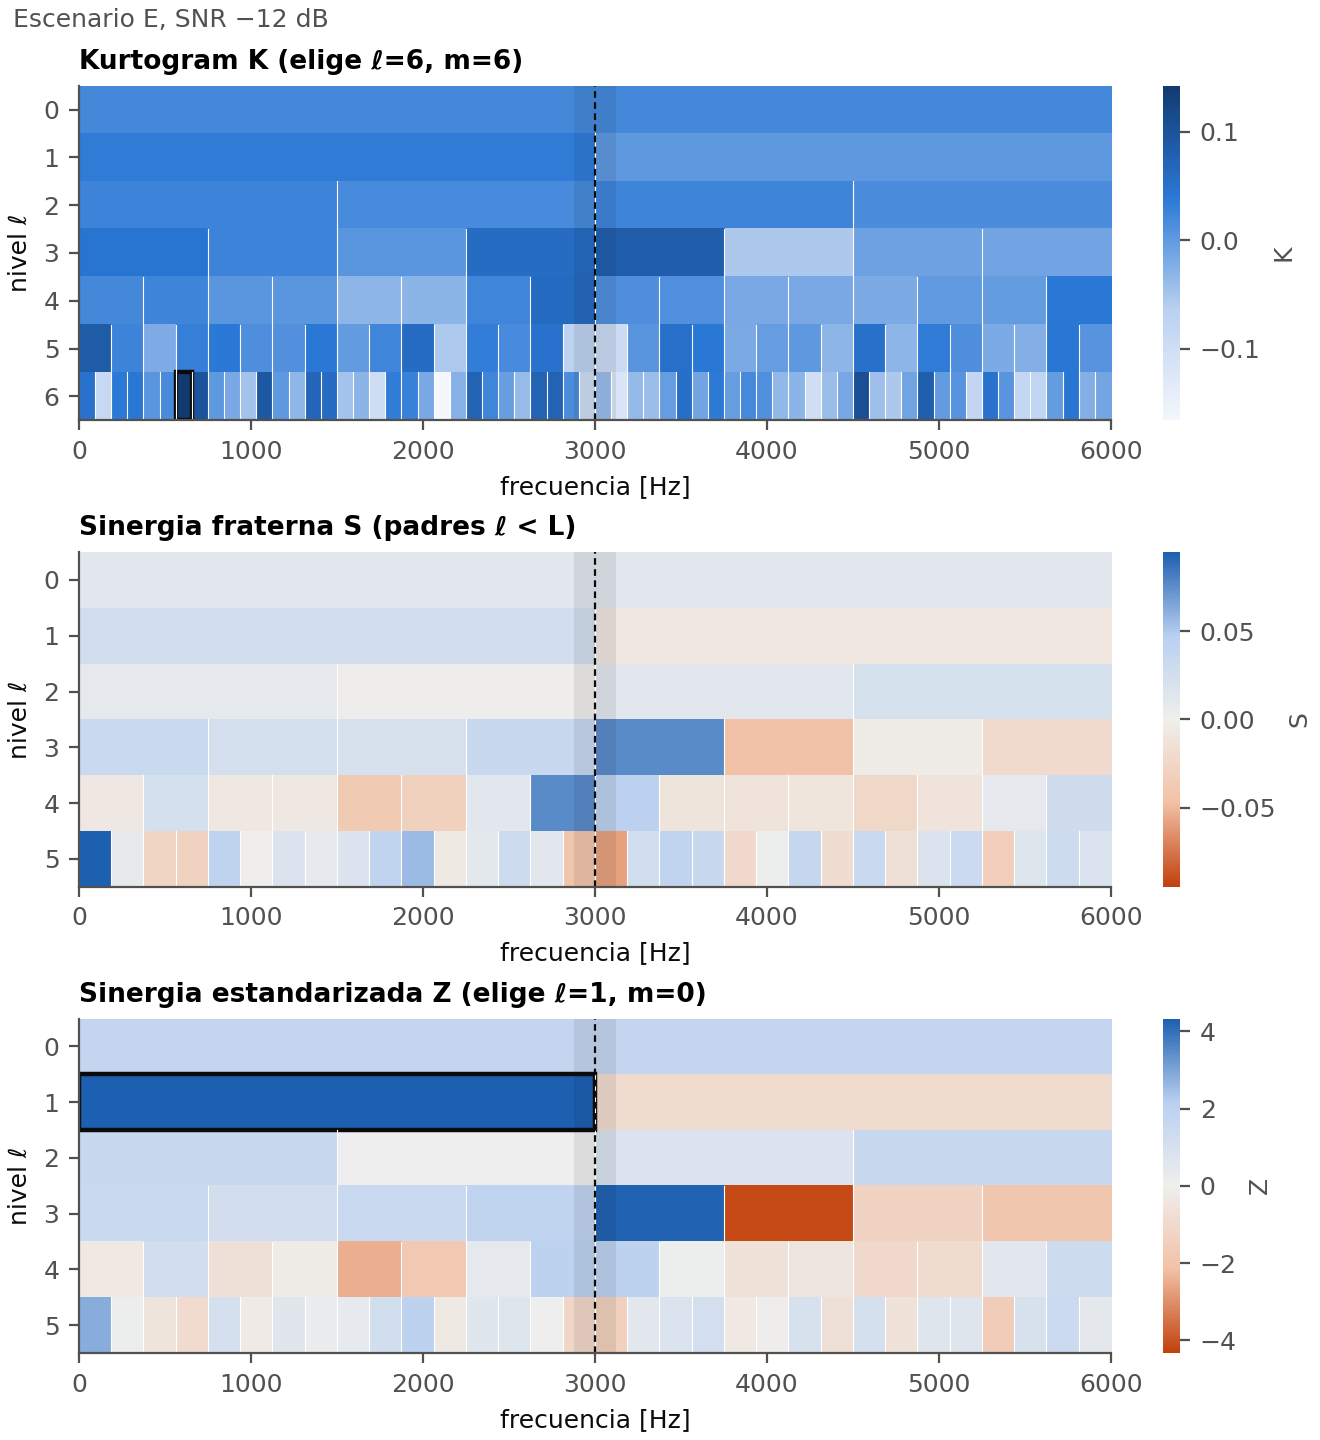

In [4]:
print(F.fig_maps_sim(dict(fn=3000), -12, 4, 'mapas_frontera.png', 'Escenario E, SNR −12 dB'))
Image('fig/mapas_frontera.png')

## 3. Descomposición a lo largo del camino raíz → resonancia

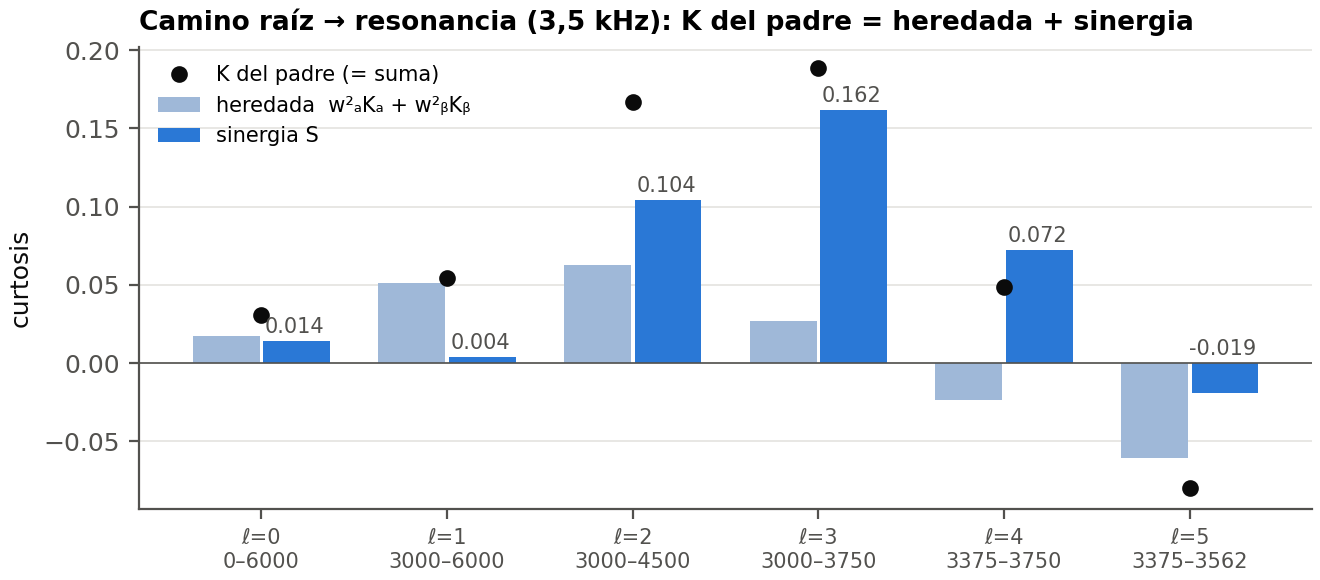

In [5]:
F.fig_heredity('herencia.png'); Image('fig/herencia.png')

## 4. Espectro de sinergia (cruzado entre hermanos) vs. SES (auto)

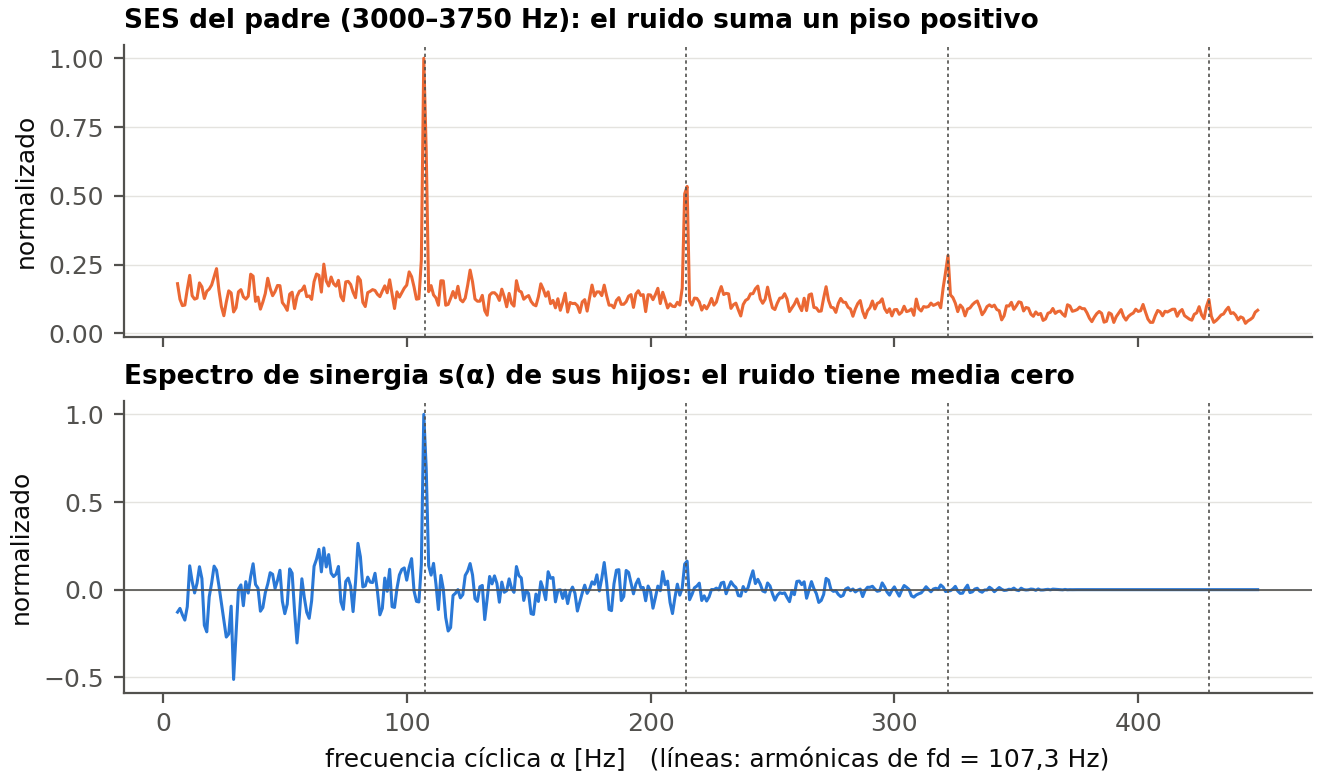

In [6]:
F.fig_ses_vs_synergy('ses_vs_sinergia.png'); Image('fig/ses_vs_sinergia.png')

## 5. CWRU
Los `.mat` del CWRU están en la carpeta `data/CWRU` del proyecto. El registro 282 corresponde al archivo `B007_0` de 12k Fan End (en el sitio original, `282.mat`).

((4, 4), (3, 2), (1, 1))


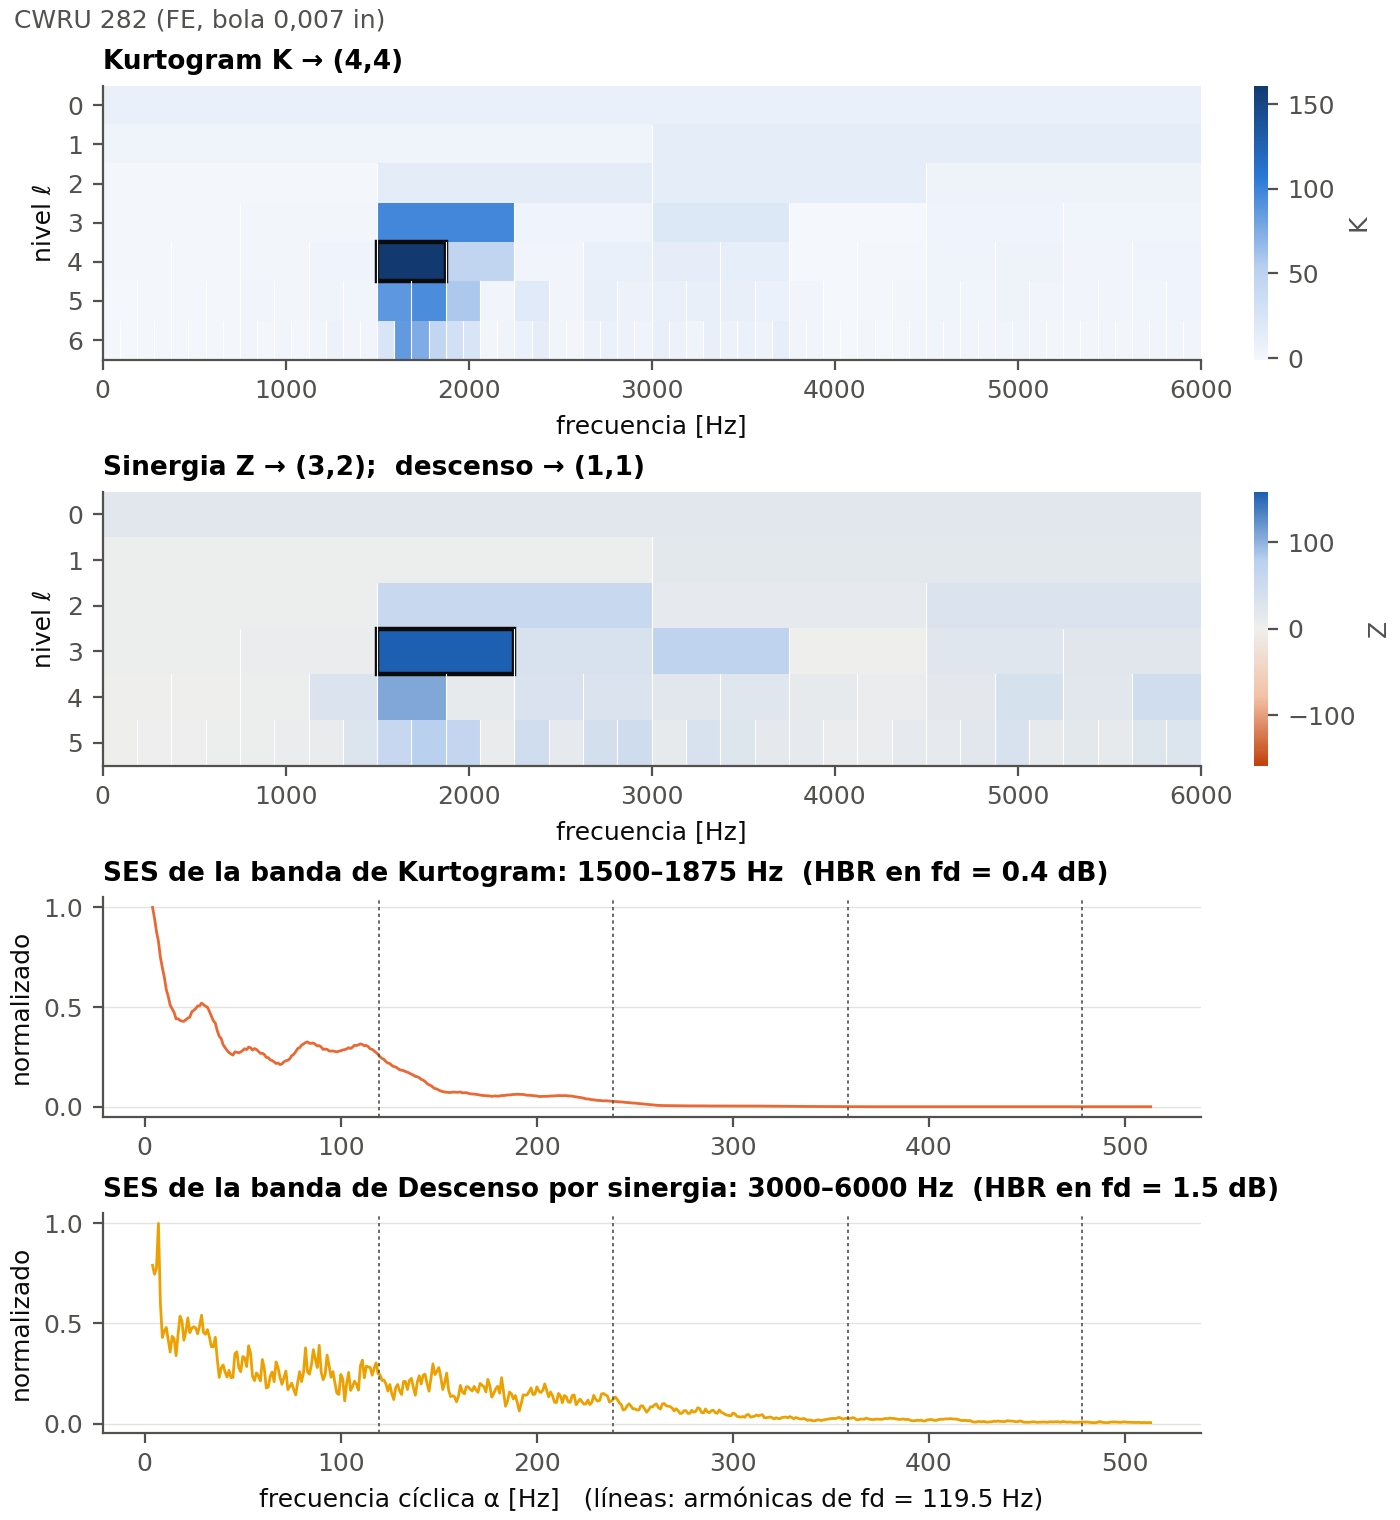

In [7]:
import os
RUTA = os.environ.get('CWRU_DATA', os.path.join('..', '..', 'data', 'CWRU'))   # carpeta data/ del proyecto
candidatos = [os.path.join(RUTA, '282.mat'), os.path.join(RUTA, '12k_FE', 'B007_0.mat')]
archivo_282 = next((c for c in candidatos if os.path.exists(c)), candidatos[0])
if os.path.exists(archivo_282):
    print(F.fig_cwru_example(archivo_282, 'FE', 'cwru_282.png', 'CWRU 282 (FE, bola 0,007 in)'))
    display(Image('fig/cwru_282.png'))
else:
    print('No se encontró', archivo_282, '— ajuste RUTA')

### Uso directo en un registro propio
Esta celda sirve de plantilla para la Tarea: calcula el kurtogram, el sinergograma y la sinergia dirigida y compara las bandas elegidas.

In [8]:
def analizar(x, fs, fd, L=6):
    T = MDFDTree(x, fs, L)
    K = kurtogram(T)
    syn = synergy_map(T, n_surr=16)
    Z = {k: v['Z'] for k, v in syn.items()}
    auto, sib, sfd = cyclic_maps(T, fd)
    elecciones = {'Kurtogram': argmax_node(K), 'Sinergia Z': argmax_node(Z),
                  'Descenso por sinergia': synergy_descent(T, syn)[0],
                  'Sinergia dirigida S_fd': argmax_node(sfd)}
    for nombre, nodo in elecciones.items():
        fc, bw = T.fc_bw(*nodo)
        hbr, det = diagnostic_score(T.z(*nodo), fs, fd, bw=bw)
        print(f'{nombre:24s} nodo={nodo}  banda={fc-bw/2:.0f}-{fc+bw/2:.0f} Hz  HBR(fd)={hbr:5.1f} dB  detecta={det}')
    return T, elecciones

_ = analizar(x, FS, 107.3)

Kurtogram                nodo=(3, 4)  banda=3000-3750 Hz  HBR(fd)= 12.3 dB  detecta=True
Sinergia Z               nodo=(2, 2)  banda=3000-4500 Hz  HBR(fd)= 12.4 dB  detecta=True
Descenso por sinergia    nodo=(2, 2)  banda=3000-4500 Hz  HBR(fd)= 12.4 dB  detecta=True
Sinergia dirigida S_fd   nodo=(3, 4)  banda=3000-3750 Hz  HBR(fd)= 12.3 dB  detecta=True
